# 08 — R2 IMU models

E1 is the 1D-CNN and E2 is the LSTM. Both read the normalised IMU window `(6, 400)` and emit one drift magnitude. Official runs come from `python scripts/train_dl.py` and use `configs/dl_config.yaml`. This notebook plots those curves, then runs a small grid on the validation block only. The test flight is not loaded for the grid.

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("OMP_NUM_THREADS", "1")
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from vio_drift.models.dl.cnn1d import receptive_field_samples, receptive_field_seconds
from vio_drift.models.dl.train import build_model, parameter_count

print(f"receptive field {receptive_field_samples()} samples ({receptive_field_seconds()*1000:.0f} ms)")
for name in ("cnn1d", "lstm"):
    model = build_model(name, dropout=0.3, out_dim=1)
    print(f"{name}: encoder {parameter_count(model.encoder):,}  full {parameter_count(model):,}")

receptive field 13 samples (65 ms)
cnn1d: encoder 24,352  full 24,417
lstm: encoder 18,432  full 18,497


## Training curves

Each curve is one leave-one-flight fold. The marked point is the validation epoch restored for the test predictions. Phase 1 Lasso, for scale, has mean test MAE 2.50 cm and R² 0.756.

experiment          fold_id  best_epoch  epochs_ran  best_train_loss  best_val_loss  best_val_mae_m  test_mae_m  test_rmse_m    test_r2  test_bias_m
        E1 leave_MH_01_easy           5          20         0.002441       0.003529        0.048523    0.101998     0.150191  -5.798120     0.054499
        E1 leave_MH_02_easy           2          17         0.028742       0.010863        0.094168    0.175329     0.275557 -11.307520     0.016730
        E2 leave_MH_01_easy          14          29         0.023258       0.000723        0.021966    0.035151     0.045291   0.381799    -0.012546
        E2 leave_MH_02_easy          27          42         0.016270       0.001333        0.027730    0.035285     0.047950   0.627322    -0.014869


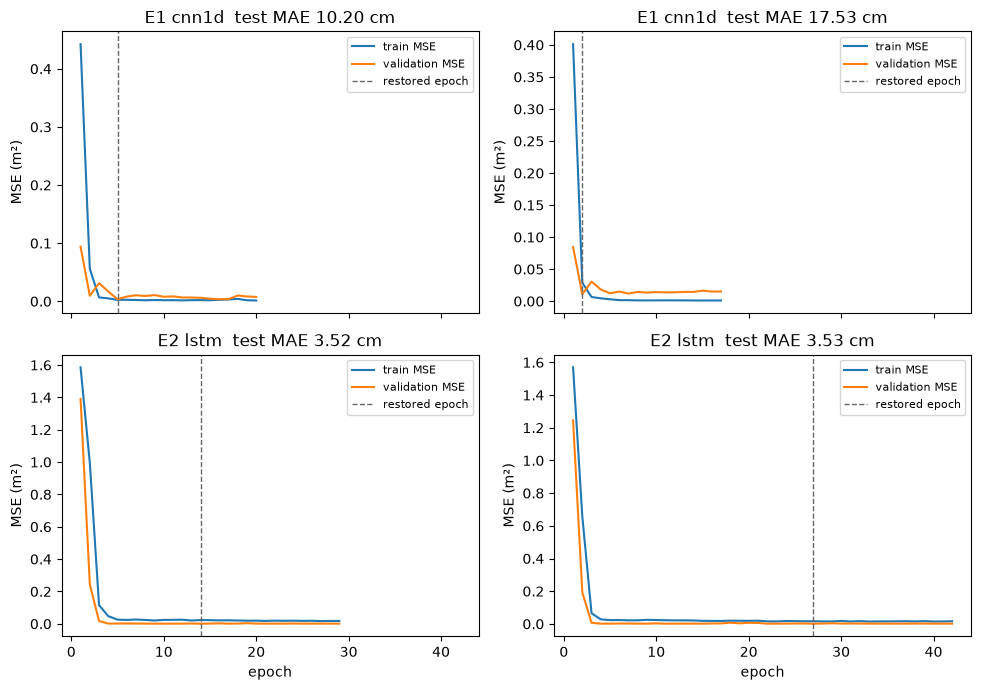

In [2]:
summary = pd.read_csv(ROOT / "results/metrics/imu_e1_e2.csv")
display_cols = ["experiment", "fold_id", "best_epoch", "epochs_ran",
                "best_train_loss", "best_val_loss", "best_val_mae_m",
                "test_mae_m", "test_rmse_m", "test_r2", "test_bias_m"]
print(summary[display_cols].to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)
for axis, row in zip(axes.ravel(), summary.itertuples(index=False)):
    curve = pd.read_csv(ROOT / f"results/metrics/{row.experiment}_{row.fold_id}_loss.csv")
    axis.plot(curve.epoch, curve.train_loss, label="train MSE")
    axis.plot(curve.epoch, curve.val_loss, label="validation MSE")
    axis.axvline(row.best_epoch, color="0.4", ls="--", lw=1, label="restored epoch")
    axis.set_title(f"{row.experiment} {row.model}  test MAE {row.test_mae_m*100:.2f} cm")
    axis.set_ylabel("MSE (m²)")
    axis.legend(fontsize=8)
for axis in axes[1]:
    axis.set_xlabel("epoch")
fig.tight_layout()
fig.savefig(ROOT / "figures/dl/imu_loss_curves.png", dpi=120)
plt.show()

## Validation grid

Eight-epoch cap, both folds, validation loss only. Settings are the config learning rate and a ten-times-smaller one, and dropout 0.3 against dropout off for the CNN. Nothing here is written over the E1/E2 checkpoints, and the test split is not constructed.

In [3]:
import json
from vio_drift.data.dl_dataset import DriftDataset
from vio_drift.models.dl.train import run_validation_grid

processed = ROOT / "data/processed"
folds = json.loads((processed / "splits_dl.json").read_text())["folds"]
settings = [
    {"model_name": "cnn1d", "learning_rate": 1e-3, "dropout": 0.3},
    {"model_name": "cnn1d", "learning_rate": 1e-3, "dropout": 0.0},
    {"model_name": "cnn1d", "learning_rate": 1e-4, "dropout": 0.3},
    {"model_name": "lstm", "learning_rate": 1e-3, "dropout": 0.3},
    {"model_name": "lstm", "learning_rate": 1e-4, "dropout": 0.3},
]
frames = []
for fold in folds:
    train_data = DriftDataset(processed, fold["fold_id"], "train", use_camera=False, seed=42)
    val_data = DriftDataset(processed, fold["fold_id"], "validation", use_camera=False, seed=42)
    grid = run_validation_grid(
        train_data, val_data, settings,
        model_name="cnn1d", epochs=8, batch_size=32, weight_decay=1e-4, seed=42,
        device="cpu", num_workers=0, early_stopping=True, patience=4, min_delta=1e-5,
        use_scheduler=True, learning_rate=1e-3, dropout=0.3,
    )
    grid.insert(0, "fold_id", fold["fold_id"])
    frames.append(grid)
grid_table = pd.concat(frames, ignore_index=True)
grid_path = ROOT / "results/metrics/imu_hparam_grid.csv"
grid_table.to_csv(grid_path, index=False)
print(grid_table.to_string(index=False))
print("wrote", grid_path)

         fold_id model_name  learning_rate  dropout  weight_decay  best_epoch  best_val_loss  best_val_mae
leave_MH_01_easy      cnn1d         0.0010      0.3        0.0001           5       0.003529      0.048523
leave_MH_01_easy      cnn1d         0.0010      0.0        0.0001           8       0.001143      0.027937
leave_MH_01_easy      cnn1d         0.0001      0.3        0.0001           8       0.130195      0.357542
leave_MH_01_easy       lstm         0.0010      0.3        0.0001           4       0.001142      0.026191
leave_MH_01_easy       lstm         0.0001      0.3        0.0001           8       1.469558      1.211619
leave_MH_02_easy      cnn1d         0.0010      0.3        0.0001           2       0.010863      0.094168
leave_MH_02_easy      cnn1d         0.0010      0.0        0.0001           6       0.001614      0.031433
leave_MH_02_easy      cnn1d         0.0001      0.3        0.0001           8       0.132709      0.359017
leave_MH_02_easy       lstm         0